## def founction*

In [41]:
instance = {}
solution = {}

def density_of_a_graph(instance):

    num_vertices = len(instance["node_coord"])
    num_edges = sum(len(neighbors) for neighbors in instance["edges"].values()) // 2  # Diviser par 2 pour éviter le double comptage
    max_edges = num_vertices * (num_vertices - 1) / 2  # Nombre maximum d'arêtes dans un graphe simple

    if max_edges == 0:
        return 0.0  # Éviter la division par zéro pour un graphe vide ou avec un seul sommet

    density = num_edges / max_edges
    return density*100  # Retourner la densité en pourcentage


def degree_vertex(solution):
    return len(solution["routes"])



def neighbors(graph, vertex):
    return graph[vertex]

for vertex in solution["routes"][0]:
    print(f"{vertex}: {degree_vertex(solution, vertex)}")
    print(f"Neighbors of {vertex}: {neighbors(solution, vertex)}")

def is_eulerian(graph):
    for vertex in graph:
        if degree_vertex(graph, vertex) % 2 == 0:
            return True
        else:
            return False

print(f"Is the graph Eulerian? {is_eulerian(liste_zone_A_dic)}")




from    collections import deque
import  copy
import time 

def eulerian_cycle(graph, start_vertex):
    graph_copy = copy.deepcopy(graph)
    stack = [start_vertex]
    cycle = []

    while stack:
        vertex = stack[-1]
        if graph_copy[vertex]:
            next_vertex = graph_copy[vertex].pop()
            graph_copy[next_vertex].remove(vertex)
            stack.append(next_vertex)
        else:
            cycle.append(stack.pop())

    return cycle[::-1]
start = time.perf_counter()

print(f"Eulerian cycle starting from vertex 1: {eulerian_cycle(liste_zone_A_dic, 1)}")

end = time.perf_counter()
print(f"Time taken: {end - start} seconds")


KeyError: 'routes'

In [1]:
print("Hello, World!")

Hello, World!


In [17]:
import vrplib

#test
instance = vrplib.read_instance("mini.vrp")

print(instance.keys())

print(instance['name'])
print(instance['dimension'])
print(instance['capacity'])
print(instance['demand'])
print(instance['node_coord'])
print(instance['depot'])
print(instance['edge_weight_type'])
print(instance['edge_weight'])

print("----------------------------------------------------------------")
print("----------------------------------------------------------------")
print(instance['depot'])
distance = instance['edge_weight']
print(distance[0][6])


dict_keys(['name', 'type', 'comment', 'dimension', 'vehicles', 'capacity', 'edge_weight_type', 'node_coord', 'demand', 'depot', 'edge_weight'])
MiniCVRP
7
10
[0 4 4 3 2 5 3]
[[0 0]
 [2 2]
 [2 6]
 [5 3]
 [6 7]
 [8 2]
 [9 6]]
[0]
EUC_2D
[[ 0.          2.82842712  6.32455532  5.83095189  9.21954446  8.24621125
  10.81665383]
 [ 2.82842712  0.          4.          3.16227766  6.40312424  6.
   8.06225775]
 [ 6.32455532  4.          0.          4.24264069  4.12310563  7.21110255
   7.        ]
 [ 5.83095189  3.16227766  4.24264069  0.          4.12310563  3.16227766
   5.        ]
 [ 9.21954446  6.40312424  4.12310563  4.12310563  0.          5.38516481
   3.16227766]
 [ 8.24621125  6.          7.21110255  3.16227766  5.38516481  0.
   4.12310563]
 [10.81665383  8.06225775  7.          5.          3.16227766  4.12310563
   0.        ]]
----------------------------------------------------------------
----------------------------------------------------------------
[0]
10.816653826391969


In [18]:
import vrplib
instance = vrplib.read_instance("data/C101.txt", instance_format="solomon")
solution = vrplib.read_solution("data/C101.sol")


In [16]:
print("Instance.keys:", instance.keys())

Instance.keys: dict_keys(['name', 'vehicles', 'capacity', 'node_coord', 'demand', 'time_window', 'service_time', 'edge_weight'])


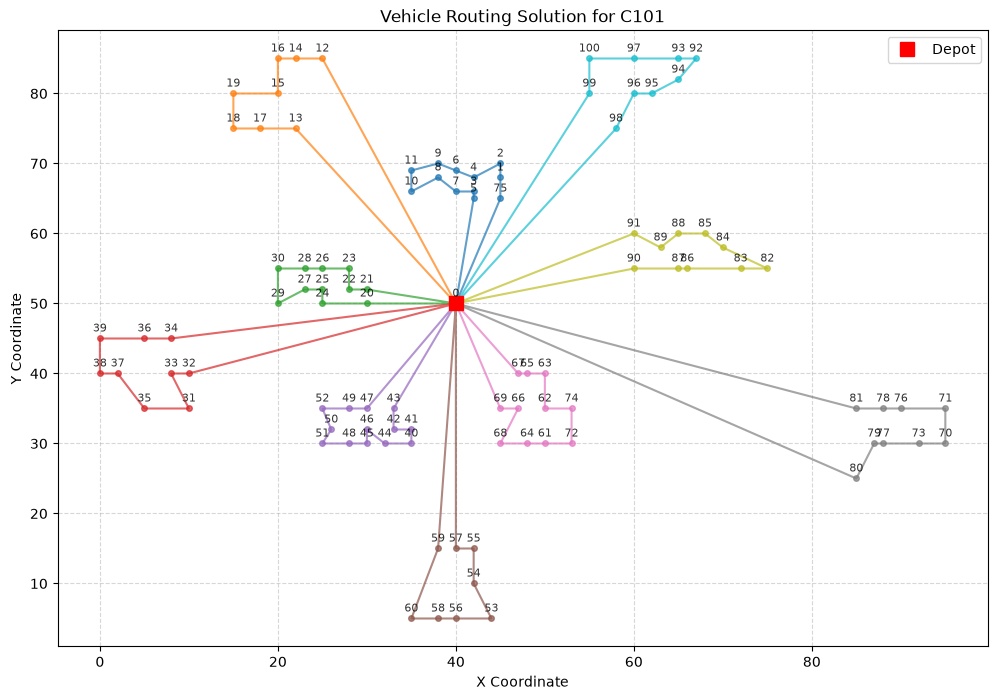

Solution routes: [[5, 3, 7, 8, 10, 11, 9, 6, 4, 2, 1, 75], [13, 17, 18, 19, 15, 16, 14, 12], [20, 24, 25, 27, 29, 30, 28, 26, 23, 22, 21], [32, 33, 31, 35, 37, 38, 39, 36, 34], [43, 42, 41, 40, 44, 46, 45, 48, 51, 50, 52, 49, 47], [57, 55, 54, 53, 56, 58, 60, 59], [67, 65, 63, 62, 74, 72, 61, 64, 68, 66, 69], [81, 78, 76, 71, 70, 73, 77, 79, 80], [90, 87, 86, 83, 82, 84, 85, 88, 89, 91], [98, 96, 95, 94, 92, 93, 97, 100, 99]]
101
Degree of the solution: 10


In [45]:
import vrplib
import matplotlib.pyplot as plt


instance = vrplib.read_instance("data/C101.txt", instance_format="solomon")
solution = vrplib.read_solution("data/C101.sol")

coords = instance["node_coord"]

# Set up the plot
plt.figure(figsize=(12, 8))


for route in solution["routes"]:
    
    full_route = [0] + route + [0]
    
    x_coords = [coords[node][0] for node in full_route]
    y_coords = [coords[node][1] for node in full_route]
    
    plt.plot(x_coords, y_coords, marker='o', markersize=4, alpha=0.7)


plt.plot(coords[0][0], coords[0][1], 'rs', markersize=10, label="Depot")

# 4. Formatting and display
plt.title(f"Vehicle Routing Solution for {instance['name']}")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
for node_index, (x, y) in enumerate(coords):
    plt.annotate(
        str(node_index),       
        (x, y),                
        textcoords="offset points", 
        xytext=(0, 5),         
        ha='center',           
        fontsize=8,            
        alpha=0.8              
    )

plt.show()

def degree_vertex(solution):
    return len(solution["routes"])

print("Solution routes:", solution["routes"])
print(len(instance["node_coord"]))
degree = degree_vertex(solution)
print(f"Degree of the solution: {degree}")

In [22]:
import vrplib
import pulp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

instance = vrplib.read_instance("data/C101.txt", instance_format="solomon")
problem = pulp.LpProblem("CVRPTW", pulp.LpMinimize)

V = range(len(instance["node_coord"]))
K = range(instance["vehicles"])

indices = [(i, j, k) for i in V for j in V if i != j for k in K]

x_ijk = {
    (i, j, k): pulp.LpVariable(
        f"x_{i}_{j}_{k}", lowBound=0, upBound=1, cat="Binary"
    )
    for i, j, k in indices
}

#CVRPTW problem
#objective fonction

Z = pulp.lpSum(instance["edge_weight"][i][j] * x_ijk[] for (i, j, k) in indices)

#constraints

#visiting each customer exactly once
for j in V:
    if j != 0:  # Exclude the depot
        problem += pulp.lpSum(x_ijk for (i, j2, k) in indices if j2 == j) == 1, f"Visit_{j}"

#flow conservation constraints
for k in K:
    for i in V:
        if i != 0:  # Exclude the depot
            problem += (pulp.lpSum(x_ijk for (i2, j, k2) in indices if i2 == i and k2 == k) -
                        pulp.lpSum(x_ijk for (i, j2, k2) in indices if j2 == i and k2 == k)) == 0, f"Flow_{i}_{k}"

#start and end at depot constraints
for k in K:
    problem += pulp.lpSum(x_ijk for (i, j, k2) in indices if i == 0 and k2 == k) == 1, f"StartDepot_{k}"
    problem += pulp.lpSum(x_ijk for (i, j, k2) in indices if j == 0 and k2 == k) == 1, f"EndDepot_{k}"

#capacity constraints
for k in K:
    problem += pulp.lpSum(instance["demand"][j] * x_ijk for (i, j, k2) in indices if k2 == k) <= instance["capacity"], f"Capacity_{k}"

#time window constraints
for k in K:
    for j in V:
        if j != 0:  # Exclude the depot
            problem += (pulp.lpSum(instance["edge_weight"][i][j] * x_ijk for (i, j2, k2) in indices if j2 == j and k2 == k) >= instance["time_window"][j][0]), f"TimeWindowStart_{j}_{k}"
            problem += (pulp.lpSum(instance["edge_weight"][i][j] * x_ijk for (i, j2, k2) in indices if j2 == j and k2 == k) <= instance["time_window"][j][1]), f"TimeWindowEnd_{j}_{k}"

#subtour elimination constraints (Miller-Tucker-Zemlin formulation)
u = pulp.LpVariable.dicts("u", V, lowBound=0, upBound=len(V)-1, cat="Continuous")
for k in K:
    for i in V:
        for j in V:
            if i != j and i != 0 and j != 0:  # Exclude the depot
                problem += u[i] - u[j] + (len(V) - 1) * x_ijk <= len(V) - 2, f"SubtourElimination_{i}_{j}_{k}"

#varialbles domain constraints
for (i, j, k) in indices:
    problem += x_ijk >= 0, f"NonNegativity_{i}_{j}_{k}"
    problem += x_ijk <= 1, f"Binary_{i}_{j}_{k}"                
      
#solve the problem
problem.solve()

print(f"Status: {pulp.LpStatus[problem.status]}")
print(f"Total cost: {pulp.value(problem.objective)}")

    




KeyboardInterrupt: 

Nombre de clients : 100
Nombre de véhicules : 25
Capacité d'un véhicule : 200.0
Demande totale : 1810.0
Capacité totale : 5000.0

Statut du solveur : Not Solved
Distance totale : 308.85
Aucune route n'a été extraite.
Valeurs des véhicules utilisés :
0 0.0
1 0.0
2 0.0
3 0.0
4 0.0
5 0.0
6 0.0
7 0.0
8 0.0
9 0.0
10 0.0
11 0.0
12 0.0
13 0.0
14 0.0
15 0.0
16 0.0
17 0.0
18 0.0
19 0.0
20 0.0
21 0.0
22 0.0
23 0.0
24 0.0


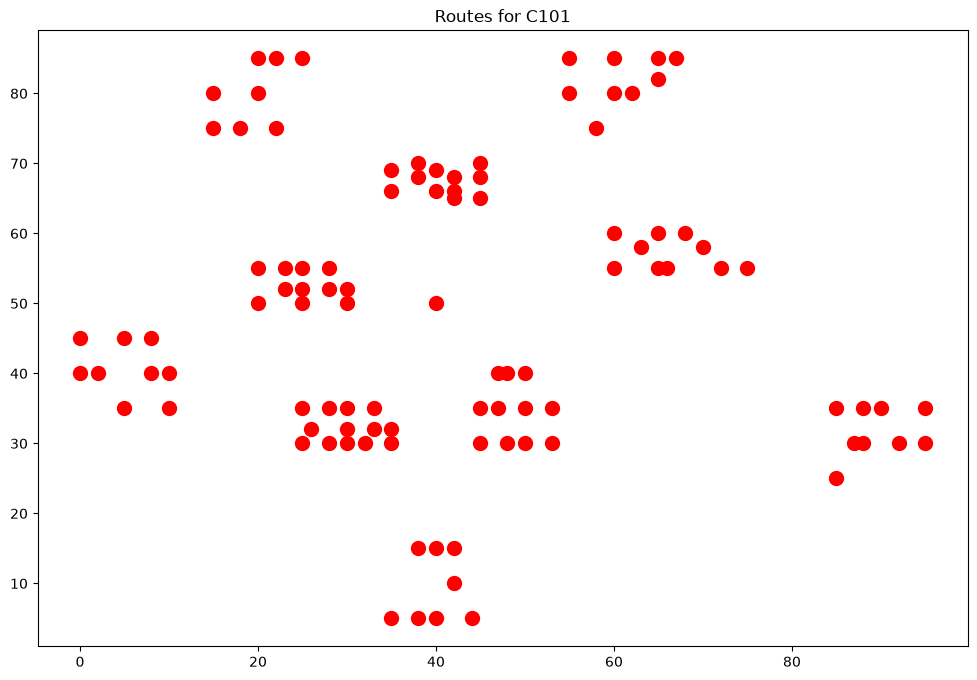

In [11]:
import vrplib
import pulp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Chargement de l'instance
# ============================================================

instance = vrplib.read_instance(
    "data/C101.txt", instance_format="solomon"
    
)

n = len(instance["node_coord"])
V = list(range(n))
customers = list(range(1, n))

number_of_vehicles = int(instance["vehicles"])
K = list(range(number_of_vehicles))

distance = np.asarray(instance["edge_weight"], dtype=float)
demand = np.asarray(instance["demand"], dtype=float)
time_window = np.asarray(instance["time_window"], dtype=float)

service_time = np.asarray(
    instance.get("service_time", np.zeros(n)),
    dtype=float
)

# Certaines instances contiennent une seule durée de service
if service_time.ndim == 0 or service_time.size == 1:
    service_time = np.full(n, float(service_time.flat[0]))
else:
    service_time = service_time.reshape(-1)

capacity = float(instance["capacity"])

print("Nombre de clients :", len(customers))
print("Nombre de véhicules :", number_of_vehicles)
print("Capacité d'un véhicule :", capacity)
print("Demande totale :", demand[1:].sum())
print("Capacité totale :", number_of_vehicles * capacity)

if demand[1:].sum() > number_of_vehicles * capacity:
    raise ValueError(
        "Instance impossible : la demande totale dépasse la capacité totale."
    )

# ============================================================
# 2. Création du modèle
# ============================================================

problem = pulp.LpProblem(
    "CVRPTW",
    pulp.LpMinimize
)

arcs = [
    (i, j)
    for i in V
    for j in V
    if i != j
]

# x[i,j,k] = 1 si le véhicule k va de i vers j
x = {
    (i, j, k): pulp.LpVariable(
        f"x_{i}_{j}_{k}",
        cat="Binary"
    )
    for i, j in arcs
    for k in K
}

# used[k] = 1 si le véhicule k est utilisé
used = {
    k: pulp.LpVariable(
        f"used_{k}",
        cat="Binary"
    )
    for k in K
}

# arrival[i,k] = heure d'arrivée du véhicule k au noeud i
arrival = {
    (i, k): pulp.LpVariable(
        f"arrival_{i}_{k}",
        lowBound=float(time_window[i, 0]),
        upBound=float(time_window[i, 1]),
        cat="Continuous"
    )
    for i in V
    for k in K
}

# ============================================================
# 3. Fonction objectif
# ============================================================

problem += pulp.lpSum(
    distance[i, j] * x[i, j, k]
    for i, j in arcs
    for k in K
), "TotalDistance"

# ============================================================
# 4. Chaque client est visité exactement une fois
# ============================================================

for customer in customers:
    problem += (
        pulp.lpSum(
            x[i, customer, k]
            for i in V
            if i != customer
            for k in K
        ) == 1,
        f"Visit_{customer}"
    )

# ============================================================
# 5. Départ, retour et conservation des flux
# ============================================================

for k in K:

    # Le véhicule part du dépôt s'il est utilisé
    problem += (
        pulp.lpSum(
            x[0, j, k]
            for j in customers
        ) == used[k],
        f"StartDepot_{k}"
    )

    # Le véhicule revient au dépôt s'il est utilisé
    problem += (
        pulp.lpSum(
            x[i, 0, k]
            for i in customers
        ) == used[k],
        f"EndDepot_{k}"
    )

    # Conservation du flux chez chaque client
    for customer in customers:

        incoming = pulp.lpSum(
            x[i, customer, k]
            for i in V
            if i != customer
        )

        outgoing = pulp.lpSum(
            x[customer, j, k]
            for j in V
            if j != customer
        )

        problem += (
            incoming == outgoing,
            f"Flow_{customer}_{k}"
        )

# Utilisation ordonnée des véhicules pour réduire la symétrie
for k in range(number_of_vehicles - 1):
    problem += (
        used[k] >= used[k + 1],
        f"VehicleSymmetry_{k}"
    )

# ============================================================
# 6. Contraintes de capacité
# ============================================================

for k in K:
    problem += (
        pulp.lpSum(
            demand[j] * x[i, j, k]
            for i, j in arcs
            if j != 0
        ) <= capacity,
        f"Capacity_{k}"
    )

# ============================================================
# 7. Contraintes de fenêtres temporelles
# ============================================================

depot_ready = float(time_window[0, 0])
depot_due = float(time_window[0, 1])

max_distance = float(distance.max())
max_service = float(service_time.max())
max_due = float(time_window[:, 1].max())
min_ready = float(time_window[:, 0].min())

M = max_due + max_distance + max_service - min_ready + 1

for k in K:

    # Heure de départ du dépôt
    problem += (
        arrival[0, k] == depot_ready,
        f"DepotDeparture_{k}"
    )

    for i, j in arcs:

        # Départ du dépôt vers un client
        if i == 0 and j != 0:
            problem += (
                arrival[j, k]
                >= arrival[0, k]
                + distance[0, j]
                - M * (1 - x[i, j, k]),
                f"DepotToCustomer_{j}_{k}"
            )

        # Déplacement d'un client vers un autre client
        elif i != 0 and j != 0:
            problem += (
                arrival[j, k]
                >= arrival[i, k]
                + service_time[i]
                + distance[i, j]
                - M * (1 - x[i, j, k]),
                f"CustomerToCustomer_{i}_{j}_{k}"
            )

    # Retour au dépôt avant la fermeture
    for i in customers:
        problem += (
            arrival[i, k]
            + service_time[i]
            + distance[i, 0]
            <= depot_due + M * (1 - x[i, 0, k]),
            f"ReturnToDepot_{i}_{k}"
        )

# ============================================================
# 8. Résolution pendant maximum 5 minutes
# ============================================================

solver = pulp.PULP_CBC_CMD(
    msg=True,
    timeLimit=600,
    presolve=True,
    cuts=True
)

problem.solve(solver)

status = pulp.LpStatus[problem.status]

print()
print("Statut du solveur :", status)

# ============================================================
# 9. Vérification du résultat
# ============================================================

if problem.status == pulp.LpStatusInfeasible:
    print("Aucune solution réalisable n'a été trouvée.")
    print("Vérifiez les capacités et les fenêtres temporelles.")

elif problem.status == pulp.LpStatusUnbounded:
    print("Le modèle est non borné.")

else:
    objective_value = pulp.value(problem.objective)

    if objective_value is None:
        print("Le solveur n'a pas fourni de solution exploitable.")
    else:
        print(f"Distance totale : {objective_value:.2f}")

        routes = []

        for k in K:

            used_value = pulp.value(used[k])

            if used_value is None or used_value < 0.5:
                continue

            route = [0]
            current = 0
            visited = {0}

            while True:

                next_nodes = [
                    j
                    for j in V
                    if j != current
                    and pulp.value(x[current, j, k]) is not None
                    and pulp.value(x[current, j, k]) > 0.5
                ]

                if not next_nodes:
                    break

                next_node = next_nodes[0]
                route.append(next_node)

                if next_node == 0:
                    break

                if next_node in visited:
                    print(
                        f"Attention : sous-tour détecté pour le véhicule {k}."
                    )
                    break

                visited.add(next_node)
                current = next_node

            route_distance = sum(
                distance[route[pos], route[pos + 1]]
                for pos in range(len(route) - 1)
            )

            route_load = sum(
                demand[node]
                for node in route
                if node != 0
            )

            routes.append({
                "vehicle": k,
                "route": route,
                "load": route_load,
                "distance": route_distance
            })

        routes_df = pd.DataFrame(routes)

        if routes_df.empty:
            print("Aucune route n'a été extraite.")
            print("Valeurs des véhicules utilisés :")
            for k in K:
                print(k, pulp.value(used[k]))
        else:
            display(routes_df)

def plot_routes(instance, routes_df, title, figsize):
    plt.figure(figsize=figsize)
    plt.title(title)

    for _, row in routes_df.iterrows():
        route = row["route"]
        for i in range(len(route) - 1):
            plt.plot([instance["node_coord"][route[i]][0], instance["node_coord"][route[i + 1]][0]], [instance["node_coord"][route[i]][1], instance["node_coord"][route[i + 1]][1]], "b-")

    plt.scatter([instance["node_coord"][i][0] for i in V], [instance["node_coord"][i][1] for i in V], c="red", s=100)
    plt.show()

plot_routes(instance, routes_df, f"Routes for {instance['name']}", (12, 8))           